<a href="https://colab.research.google.com/github/nikos0406/SVGKit/blob/3.x/NN_HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Part 0 First exploration**

**0.1 Load both files**

In [2]:
df_customers = pd.read_csv("/content/drive/MyDrive/NN_HW1/data/customers.csv")

df_usage = pd.read_csv("/content/drive/MyDrive/NN_HW1/data/monthly_usage.csv")

**0.2  Type and number of missing values**

In [3]:
print("CUSTOMERS")
print(df_customers.dtypes)
print(df_customers.isnull().sum(), '\n')

print("MONTHLY USAGE")
print(df_usage.dtypes)
print(df_usage.isnull().sum())

CUSTOMERS
customer_id            object
gender                 object
date_of_birth          object
city                   object
contract_type          object
tenure_months         float64
monthly_charge_usd    float64
num_complaints          int64
churn                  object
dtype: object
customer_id            0
gender                24
date_of_birth         43
city                  25
contract_type          0
tenure_months         48
monthly_charge_usd    36
num_complaints         0
churn                  0
dtype: int64 

MONTHLY USAGE
cust_no              int64
month               object
minutes_day        float64
minutes_evening    float64
minutes_night      float64
total_minutes      float64
sms_count            int64
data_volume        float64
data_unit           object
dtype: object
cust_no              0
month                0
minutes_day        134
minutes_evening      0
minutes_night        0
total_minutes        0
sms_count            0
data_volume          0
data_unit  

**0.3  Distinc values**

In [4]:
columns = ["gender", "city", "contract_type", "churn"]

for c in columns:
  print(c, ':', df_customers[c].unique())

gender : ['M' 'F' ' M' 'f' 'm' nan 'Male' 'F ' 'Female' 'male' 'female']
city : ['Kinshasa' 'Addis Ababa' nan 'Gonder' 'Hawassa' 'Goma' 'Gondar'
 'Kisangani' 'Bahir Dar' 'ADDIS ABABA' 'kinshasa' 'Kinshasa ' 'goma'
 'Lubumbashi' 'Awassa' 'KINSHASA' 'addis ababa' 'Bahirdar' 'bahir dar'
 'lubumbashi' 'kisangani' 'Lubumbachi' 'Addis-Ababa']
contract_type : ['Postpaid' 'Prepaid' 'Post-paid' 'prepaid' 'Pre-paid' 'PREPAID'
 'POSTPAID' 'postpaid']
churn : ['Yes' 'No']


What i noticed:
- Many different descriptions are used for the same category
- 'nan' in gender category

**0.4  Min max numeric columns**

In [5]:
numeric_columns_customers = ["tenure_months", "monthly_charge_usd", "num_complaints"]

print("CUSTOMERS:", '\n')

for nc in numeric_columns_customers:
  print("MAX:", nc, df_customers[nc].max())

for nc in numeric_columns_customers:
  print("MIN:", nc, df_customers[nc].min())

print('\n')


numeric_columns_monthly = ["cust_no", "minutes_day", "minutes_evening", "minutes_night",
                           "total_minutes", "sms_count", "data_volume"]

print("MONTHLY USAGE:", '\n')

for nc in numeric_columns_monthly:
  print("MAX:", nc, df_usage[nc].max())

for nc in numeric_columns_monthly:
  print("MIN:", nc, df_usage[nc].min())

CUSTOMERS: 

MAX: tenure_months 96.0
MAX: monthly_charge_usd 9999.0
MAX: num_complaints 5
MIN: tenure_months -12.0
MIN: monthly_charge_usd 8.43
MIN: num_complaints 0


MONTHLY USAGE: 

MAX: cust_no 1383
MAX: minutes_day 1860.3
MAX: minutes_evening 1241.4
MAX: minutes_night 376.9
MAX: total_minutes 3473.7
MAX: sms_count 315
MAX: data_volume 9999999.0
MIN: cust_no 1
MIN: minutes_day 13.1
MIN: minutes_evening 0.0
MIN: minutes_night 0.0
MIN: total_minutes 13.1
MIN: sms_count 5
MIN: data_volume -1.0


Impossible numbers I found:
- CUSTOMERS
  - tenure_months min = -12
  - monthly_charge_usd max = 9999

- MONTHLY USAGE
  - data_volume min = -1, max = 999999999999

**0.5  Monthly charge histogram & data  volume box plot**

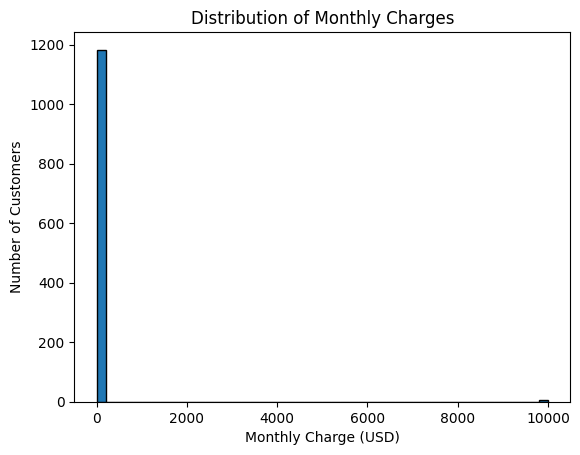

In [6]:
charges = df_customers["monthly_charge_usd"]

plt.hist(charges, bins=50, edgecolor="black")

plt.xlabel("Monthly Charge (USD)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Monthly Charges")

plt.show()

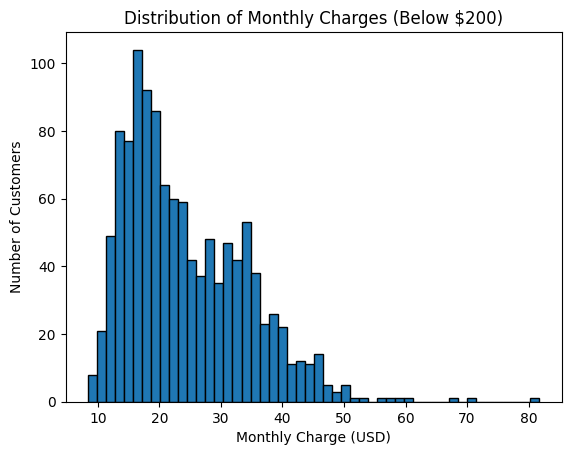

In [7]:

charges = df_customers["monthly_charge_usd"]

plt.hist(charges[charges < 200], bins=50, edgecolor="black")

plt.xlabel("Monthly Charge (USD)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Monthly Charges (Below $200)")

plt.show()

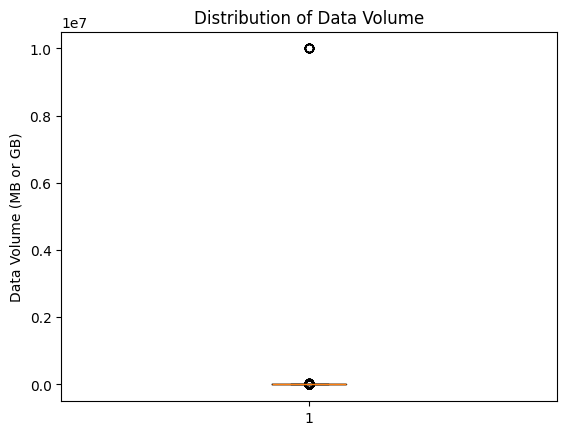

In [8]:
usage = df_usage["data_volume"]

plt.boxplot(usage)

plt.ylabel("Data Volume (MB or GB)")
plt.title("Distribution of Data Volume")

plt.show()

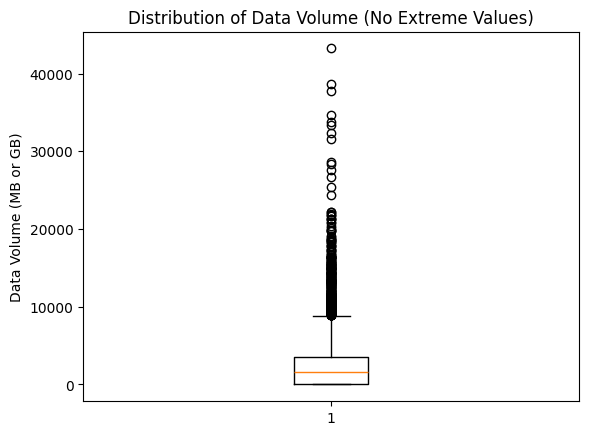

In [10]:
usage = df_usage["data_volume"]

plt.boxplot(usage[usage < 500000])

plt.ylabel("Data Volume (MB or GB)")
plt.title("Distribution of Data Volume (No Extreme Values)")

plt.show()

**0.6  Issues**
- Different description format for same categories
- Missing datapoints
- Impossible data points

# **Part 1 Data cleaning**

**1.1  Duplicates**

In [27]:
print("Duplicates CUSTOMERS:", df_customers.duplicated().sum())
print("Duplicates MONTHLY USAGE:", df_usage.duplicated().sum())

customers = df_customers.drop_duplicates()
usage = df_usage.drop_duplicates()

print("\nDuplicates CUSTOMERS:", customers.duplicated().sum())
print("Duplicates MONTHLY USAGE:", usage.duplicated().sum())

Duplicates CUSTOMERS: 25
Duplicates MONTHLY USAGE: 30

Duplicates CUSTOMERS: 0
Duplicates MONTHLY USAGE: 0


In [28]:
print("Duplicated customer_id:", customers["customer_id"].duplicated().sum())

print("Duplicated cust_no, month pairs:", usage.duplicated(subset=["cust_no", "month"]).sum())

Duplicated customer_id: 0
Duplicated cust_no, month pairs: 0


**1.2  Inconsistent data**